<a href="https://colab.research.google.com/github/leejsya/BreastMNIST/blob/main/BreastMNIST_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### 데이터 준비

In [ ]:
seed = 42
import numpy as np
import torch
import matplotlib.pyplot as plt

# npz 데이터 로드
data = np.load("breastmnist.npz")

In [ ]:
# npz 파일 key 확인
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


In [ ]:
# train_images/labels의 shape 확인
imgs = data['train_images']
labels = data['train_labels']
print(f"images(개수, 높이, 너비): {imgs.shape}")
print(f"labels(개수, 라벨): {labels.shape}")

images(개수, 높이, 너비): (546, 224, 224)
labels(개수, 라벨): (546, 1)


#### 샘플 이미지 확인

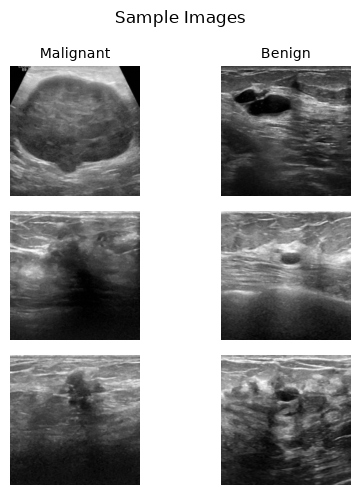

In [ ]:
# 라벨이 0인 데이터들의 인덱스 목록
idx_0 = np.where(labels==0)[0]
# 라벨이 1인 데이터들의 인덱스 목록
idx_1 = np.where(labels==1)[0]

fig, axes = plt.subplots(3, 2, figsize=(5, 5))
for i, ax in enumerate(axes.flat):
    if i % 2 == 0:
        ax.imshow(imgs[idx_0][i], cmap='gray')
        ax.axis('off')
        if i == 0:
            ax.set_title("Malignant", fontsize=10)
    else:
        ax.imshow(imgs[idx_1][i], cmap='gray')
        ax.axis('off')
        if i == 1:
            ax.set_title("Benign", fontsize=10)
plt.suptitle("Sample Images")
plt.tight_layout()
plt.show()

In [ ]:
# 라벨이 0인 이미지들
imgs_0 = imgs[idx_0]
# 라벨이 1인 이미지들
imgs_1 = imgs[idx_1]

# 각 라벨 이미지의 평균 픽셀값
print(f"imgs_0_mean: {imgs_0.mean()}")
print(f"imgs_1_mean: {imgs_1.mean()}\n")

# 각 라벨 이미지의 픽셀값 표준편차
print(f"imgs_0_std: {imgs_0.std()}")
print(f"imgs_1_std: {imgs_1.std()}")

imgs_0_mean: 78.19751806972789
imgs_1_mean: 85.53604669957738

imgs_0_std: 56.50465076159029
imgs_1_std: 55.62146857895486


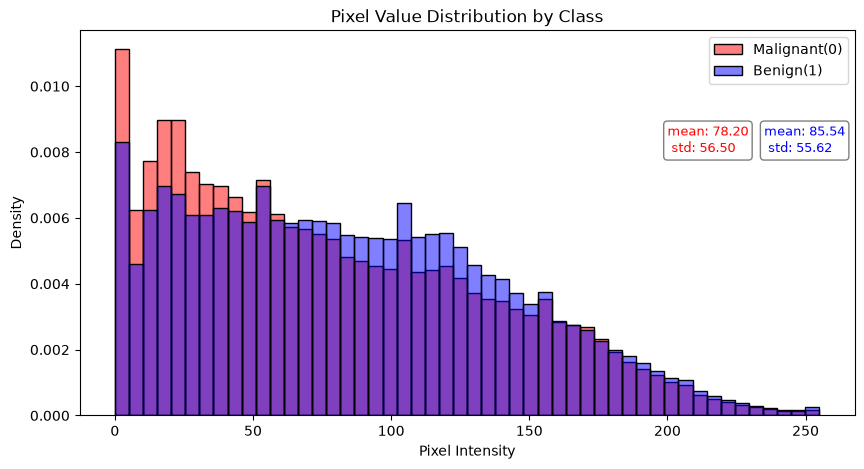

In [ ]:
import seaborn as sns

# 라벨이 0인 이미지의 모든 픽셀값 리스트
pixels_0 = imgs_0.flatten()
# 라벨이 1인 이미지의 모든 픽셀값 리스트
pixels_1 = imgs_1.flatten()

# 라벨이 0인 이미지들의 픽셀값 분포
plt.figure(figsize=(10, 5))
sns.histplot(
    pixels_0,
    color='red',
    label='Malignant(0)',
    stat='density',
    common_norm=False,
    bins=50,
    alpha=0.5
)
# 라벨이 1인 이미지들의 픽셀값 분포
sns.histplot(
    pixels_1,
    color='blue',
    label='Benign(1)',
    stat='density',
    common_norm=False,
    bins=50,
    alpha=0.5
)
plt.title("Pixel Value Distribution by Class")
plt.xlabel("Pixel Intensity")
plt.ylabel("Density")
plt.legend()
plt.text(
    x=200, y=0.008,
    s=f"mean: {imgs_0.mean():.2f}\n std: {imgs_0.std():.2f}",
    fontsize=9, color='red',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.5)
)
plt.text(
    x=235, y=0.008,
    s=f"mean: {imgs_1.mean():.2f}\n std: {imgs_1.std():.2f}",
    fontsize=9, color='blue',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.5)
)
plt.show()

#### 샘플 수 & 분포 확인

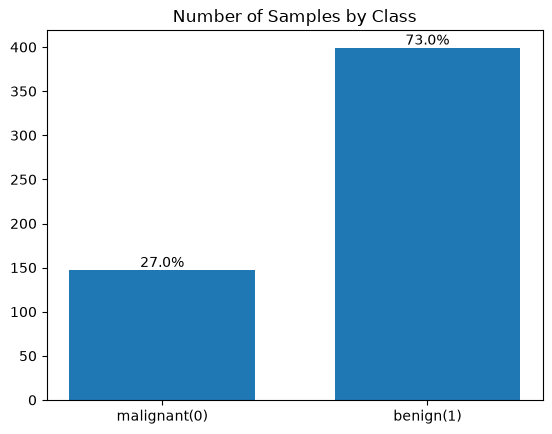

In [ ]:
# 라벨별 샘플 수 확인
bar1 = plt.bar(['malignant(0)', 'benign(1)'], [len(idx_0), len(idx_1)], width=0.7)
ratio_0 = round(len(idx_0)/(len(idx_0)+len(idx_1)), 2)
ratio_1 = 1 - ratio_0
plt.bar_label(
    bar1,
    labels=[f"{ratio_0*100}%", f"{ratio_1*100}%"]
)
plt.title("Number of Samples by Class")
plt.show()

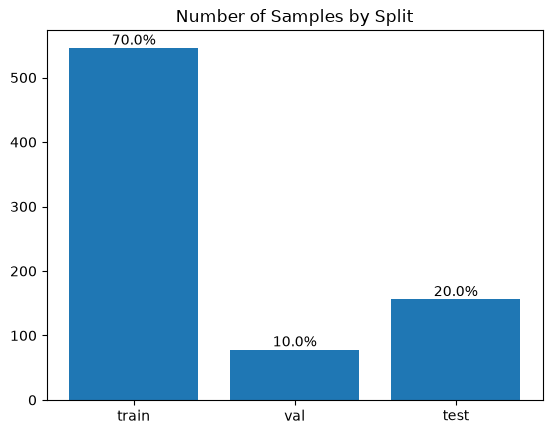

In [ ]:
# train/val/test별 샘플 수 확인
n_train = len(data['train_images'])
n_val = len(data['val_images'])
n_test = len(data['test_images'])
ratio_train = round(n_train / (n_train + n_val + n_test), 3)
ratio_val = round(n_val / (n_train + n_val + n_test), 3)
ratio_test = round(1 - ratio_train - ratio_val, 3)

bar2 = plt.bar(['train','val', 'test'], [n_train, n_val, n_test])
plt.bar_label(
    bar2,
    labels=[f"{ratio_train*100}%", f"{ratio_val*100}%", f"{ratio_test*100}%"]
)
plt.title("Number of Samples by Split")
plt.show()

In [ ]:
# train/val/test 커스텀 분할
from sklearn.model_selection import train_test_split

all_images = np.concatenate([data['train_images'], data['val_images'], data['test_images']], axis=0)
all_labels = np.concatenate([data['train_labels'], data['val_labels'], data['test_labels']], axis=0)

temp_indices, test_indices = train_test_split(
    range(len(all_images)),
    test_size=0.2,
    stratify=all_labels,
    random_state=seed
)

train_indices, val_indices = train_test_split(
    temp_indices,
    test_size=0.25,
    stratify=all_labels[temp_indices],
    random_state=seed
)

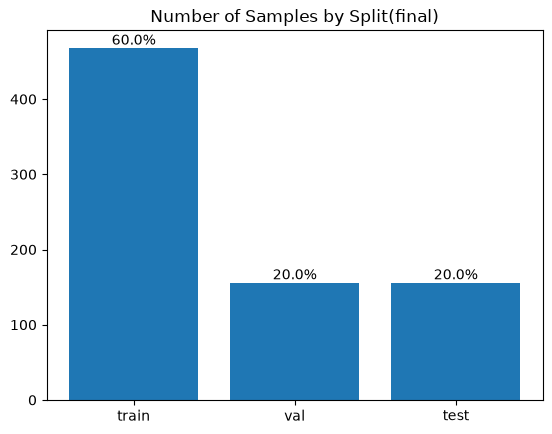

In [ ]:
bar3 = plt.bar(['train', 'val', 'test'], [len(train_indices), len(val_indices), len(test_indices)])
plt.bar_label(
    bar3,
    labels=[f"{len(train_indices)/len(all_labels)*100}%", f"{len(val_indices)/len(all_labels)*100}%", f"{len(test_indices)/len(all_labels)*100}%"]
)
plt.title("Number of Samples by Split(final)")
plt.show()

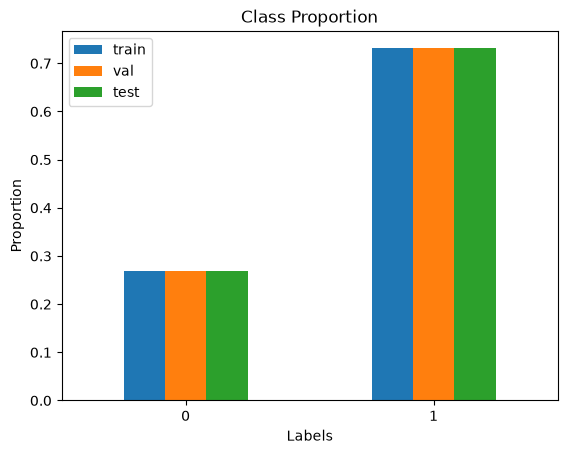

In [ ]:
# train/val/test 클래스 비율 확인
import pandas as pd

labels_dict = {
    'train_labels' : all_labels[train_indices],
    'val_labels' : all_labels[val_indices],
    'test_labels' : all_labels[test_indices]
}
prop_dict = {}
for split in ['train', 'val', 'test']:
    uniques, counts = np.unique(labels_dict[f"{split}_labels"], return_counts=True)
    prop_dict[split] = counts/counts.sum()

prop_df = pd.DataFrame(prop_dict)
prop_df.plot.bar(rot=0)
plt.xlabel("Labels")
plt.ylabel("Proportion")
plt.title("Class Proportion")
plt.show()

#### Pre-trained 모델 정보 가져오기

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights

# pre-trained 모델의 파라미터 가져오기
weights = ResNet18_Weights.IMAGENET1K_V1
# pre-trained 모델 가져오기
model = resnet18(weights=weights)
# pre-trained 모델의 transform 가져오기
model_transform = weights.transforms()

In [ ]:
# 모델 구조 확인
from torchinfo import summary

summary(
    model,
    input_size=(1, 3, 224, 244),
    # 파라미터 개수, trainable 여부 표시
    col_names=['num_params', 'trainable'],
    # layer의 변수명 표시
    row_settings=['var_names'],
    # 블록 단위로만 표시
    depth=2,
)

Layer (type (var_name))                  Param #                   Trainable
ResNet (ResNet)                          --                        True
├─Conv2d (conv1)                         9,408                     True
├─BatchNorm2d (bn1)                      128                       True
├─ReLU (relu)                            --                        --
├─MaxPool2d (maxpool)                    --                        --
├─Sequential (layer1)                    --                        True
│    └─BasicBlock (0)                    73,984                    True
│    └─BasicBlock (1)                    73,984                    True
├─Sequential (layer2)                    --                        True
│    └─BasicBlock (0)                    230,144                   True
│    └─BasicBlock (1)                    295,424                   True
├─Sequential (layer3)                    --                        True
│    └─BasicBlock (0)                    919,040               

In [ ]:
import torch.nn as nn
# Backbone 전체 고정
for p in model.parameters():
    p.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, 1)

# Backbone 고정 및 FC Layer 교체 후 모델 구조 다시 확인
summary(
    model,
    input_size=(1, 3, 224, 244),
    # 파라미터 개수, trainable 여부 표시
    col_names=['num_params', 'trainable'],
    # layer의 변수명 표시
    row_settings=['var_names'],
    # 블록 단위로만 표시
    depth=2,
)

Layer (type (var_name))                  Param #                   Trainable
ResNet (ResNet)                          --                        Partial
├─Conv2d (conv1)                         (9,408)                   False
├─BatchNorm2d (bn1)                      (128)                     False
├─ReLU (relu)                            --                        --
├─MaxPool2d (maxpool)                    --                        --
├─Sequential (layer1)                    --                        False
│    └─BasicBlock (0)                    (73,984)                  False
│    └─BasicBlock (1)                    (73,984)                  False
├─Sequential (layer2)                    --                        False
│    └─BasicBlock (0)                    (230,144)                 False
│    └─BasicBlock (1)                    (295,424)                 False
├─Sequential (layer3)                    --                        False
│    └─BasicBlock (0)                    (919,040) 

In [ ]:
# device 설정
device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
model.to(device)
print(device)

mps


In [ ]:
# model_transform 확인
print(model_transform)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [ ]:
# model_transform 내부코드 확인
import inspect
print(inspect.getsource(type(model_transform).forward))

    def forward(self, img: Tensor) -> Tensor:
        img = F.resize(img, self.resize_size, interpolation=self.interpolation, antialias=self.antialias)
        img = F.center_crop(img, self.crop_size)
        if not isinstance(img, Tensor):
            img = F.pil_to_tensor(img)
        img = F.convert_image_dtype(img, torch.float)
        img = F.normalize(img, mean=self.mean, std=self.std)
        return img



In [ ]:
# model_transform의 mean과 std값만 사용
base_mean = model_transform.mean
base_std = model_transform.std

print(base_mean)
print(base_std)

[0.485, 0.456, 0.406]
[0.229, 0.224, 0.225]


#### Transforms

In [ ]:
from torchvision.transforms import v2

train_transform = v2.Compose(
    [
        v2.ToImage(),
        # 3채널로 확장
        v2.Grayscale(num_output_channels=3),
        v2.RandomHorizontalFlip(),
        v2.RandomResizedCrop(size=224, scale=(0.8, 1.0)),
        v2.RandomRotation(degrees=10),
        v2.ToDtype(dtype=torch.float32, scale=True),
        # pre-trained 모델을 기준으로 normalize
        v2.Normalize(mean=base_mean, std=base_std)
    ]
)

eval_transform = v2.Compose(
    [
        v2.ToImage(),
        # 3채널로 확장
        v2.Grayscale(num_output_channels=3),
        v2.ToDtype(dtype=torch.float32, scale=True),
        # pre-trained 모델을 기준으로 normalize
        v2.Normalize(mean=base_mean, std=base_std)
    ]
)


#### Dataset

In [ ]:
from torch.utils.data import Dataset

class BMNISTDataset(Dataset):
    def __init__(self, indices, transform):
        self.images = all_images[indices]
        self.labels = all_labels[indices]
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # image는 transform을 적용시키면 자동으로 텐서로 변환됨.
        image_tensor = self.transform(self.images[idx])
        label_tensor = torch.tensor(self.labels[idx], dtype=torch.float32)

        return image_tensor, label_tensor

In [ ]:
train_dataset = BMNISTDataset(
    indices=train_indices,
    transform=train_transform
)
val_dataset = BMNISTDataset(
    indices=val_indices,
    transform=eval_transform
)
test_dataset = BMNISTDataset(
    indices=test_indices,
    transform=eval_transform
)

#### DataLoader

In [ ]:
from torch.utils.data import DataLoader

torch.manual_seed(seed)
train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=48,
    shuffle=True
)
val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=36,

)
test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=36
)

#### Training Loop

In [ ]:
# loss function
loss_fn = nn.BCEWithLogitsLoss()

In [ ]:
# Evaluation Function
def evaluate(dataloader, model, loss_fn):
    model.eval()
    losses = []
    correct, total = 0, 0
    all_preds = []
    all_probs = []
    with torch.no_grad():
        for batch in dataloader:
            inputs, labels = batch[0].to(device), batch[1].to(device)
            logits = model(inputs)

            loss = loss_fn(logits, labels)
            losses.append(loss.item())

            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).long()
            avg_loss = sum(losses) / len(losses)
            correct += (preds == labels).sum().item()
            total += len(logits)
            acc = correct / total
            all_preds.extend(preds.cpu())
            all_probs.extend(probs.cpu())
    return avg_loss, acc, all_preds, all_probs


In [ ]:
loss_history = []
acc_history = []
def Train_Loop(dataloader, model, optimizer, epochs, min_loss):
    model.train()
    for epoch in range(epochs):
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d): # and not m.weight.requires_grad:
                m.eval()

        for train_batch in dataloader:
            inputs, labels = train_batch[0].to(device), train_batch[1].to(device)
            logits = model(inputs)

            loss = loss_fn(logits, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        val_loss, val_acc, _, _ = evaluate(val_dataloader, model, loss_fn)
        loss_history.append(val_loss)
        acc_history.append(val_acc)
        if min_loss >= val_loss:
            min_loss = val_loss
            torch.save(model.state_dict(), 'model.pt')
    return min_loss

#### Step 1(FC Layer)

In [ ]:
import torch.optim as optim

min_loss = float('inf')

# 1단계 학습을 위한 optimizer
optimizer1 = optim.Adam(model.fc.parameters(), lr=1e-3)

# 1단계 학습 진행
min_loss = Train_Loop(
    dataloader=train_dataloader,
    model=model,
    optimizer=optimizer1,
    epochs=10,
    min_loss=min_loss
)

#### Step 2(Layer4 + FC Layer)

In [ ]:
for p in model.layer4.parameters():
    p.requires_grad = True

summ = summary(
    model,
    input_size=(1, 3, 224, 244),
    # 파라미터 개수, trainable 여부 표시
    col_names=['num_params', 'trainable'],
    # layer의 변수명 표시
    row_settings=['var_names'],
    # 블록 단위로만 표시
    depth=2,
)

# summary를 호출했을 때 모델이 CUDA에 있는 게 아니라면 강제로 모델이 CPU로 옮겨감.
model.to(device)
print(summ)

Layer (type (var_name))                  Param #                   Trainable
ResNet (ResNet)                          --                        Partial
├─Conv2d (conv1)                         (9,408)                   False
├─BatchNorm2d (bn1)                      (128)                     False
├─ReLU (relu)                            --                        --
├─MaxPool2d (maxpool)                    --                        --
├─Sequential (layer1)                    --                        False
│    └─BasicBlock (0)                    (73,984)                  False
│    └─BasicBlock (1)                    (73,984)                  False
├─Sequential (layer2)                    --                        False
│    └─BasicBlock (0)                    (230,144)                 False
│    └─BasicBlock (1)                    (295,424)                 False
├─Sequential (layer3)                    --                        False
│    └─BasicBlock (0)                    (919,040) 

In [ ]:
# 2단계 학습을 위한 optimizer
optimizer2 = optim.Adam(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-5
)

# 2단계 학습을 진행하기 전, 모델을 성능이 가장 좋았던 모델로 로드
model.load_state_dict(torch.load('model.pt', map_location=device))

# 2단계 학습 진행
min_loss = Train_Loop(
    dataloader=train_dataloader,
    model=model,
    optimizer=optimizer2,
    epochs=20,
    min_loss=min_loss
)

#### Test

In [ ]:
model.load_state_dict(torch.load('model.pt', map_location=device))
test_loss, test_acc, all_preds, all_probs = evaluate(test_dataloader, model, loss_fn)
print(f"test loss: {test_loss:.4f}, test acc: {test_acc:.4f}")

test loss: 0.4252, test acc: 0.8590


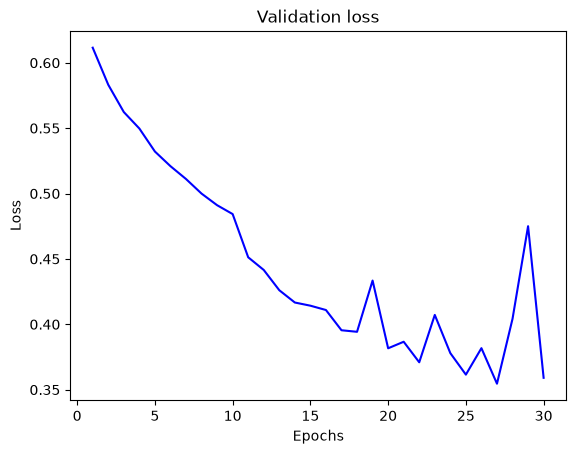

In [ ]:
plt.plot(range(1, len(loss_history)+1), loss_history, 'b', label="Validation loss")
plt.title("Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

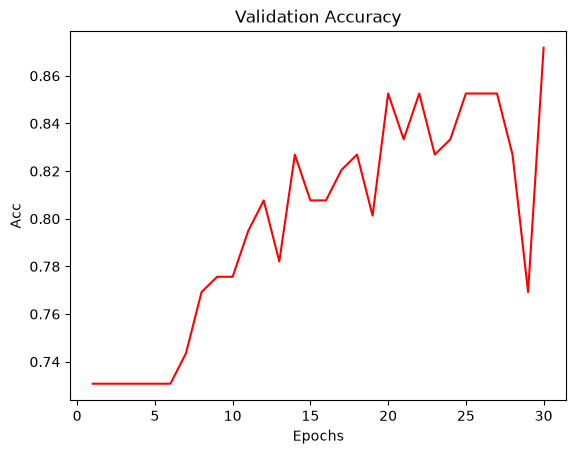

In [ ]:
plt.plot(range(1, len(acc_history)+1), acc_history, 'r', label='Validation accuracy')
plt.title("Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Acc")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(all_labels[test_indices], all_preds, output_dict=True)
print(classification_report(all_labels[test_indices], all_preds))

              precision    recall  f1-score   support

           0       0.83      0.60      0.69        42
           1       0.87      0.96      0.91       114

    accuracy                           0.86       156
   macro avg       0.85      0.78      0.80       156
weighted avg       0.86      0.86      0.85       156



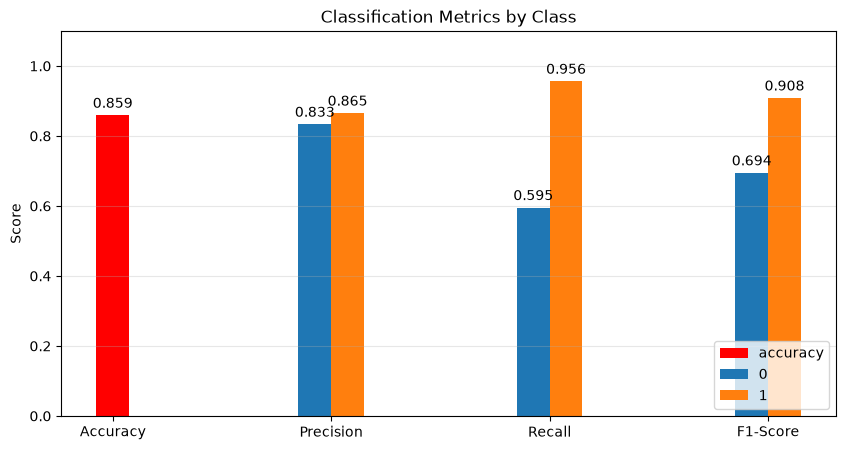

In [ ]:
classes = ['0', '1']
metrics = ['precision', 'recall', 'f1-score']
accuracy = report['accuracy']

x = np.arange(len(metrics)) + 1
width = 0.15

fig, ax = plt.subplots(figsize=(10,5))

acc_bar = ax.bar(0, accuracy, width, color='r', label='accuracy')
ax.bar_label(acc_bar, fmt='%.3f', padding=3)

for i, cls in enumerate(classes):
    values = [report[cls][m] for m in metrics]
    bars = ax.bar(x + (i - 0.5) * width, values, width, label=cls)
    ax.bar_label(bars, fmt='%.3f', padding=3)

ax.set_xticks(np.arange(len(metrics) + 1), ['Accuracy', 'Precision', 'Recall', 'F1-Score'])
ax.set_ylabel('Score')
ax.set_ylim(0, 1.1)
ax.set_title('Classification Metrics by Class')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)
plt.show()

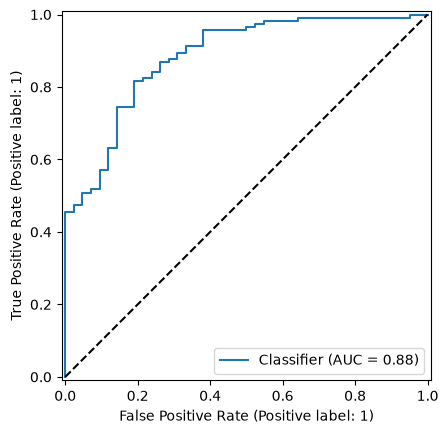

In [ ]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(all_labels[test_indices], all_probs)
plt.plot([0,1], [0,1], "k--")
plt.show()